Task 1: Print dataset dimensions, feature summary statistics, and missing value checks. Standardize all 13 features and display a comparison of feature distributions before and after scaling.

Explanation: Loads the Wine dataset with load_wine and prints the shape, the class distribution, describe() and the missing values in each column. I then standardize all 13 features with StandardScaler and print the mean and standard deviation of each feature before and after scaling. I also print the share of the squared distance between two wines that each raw feature contributes, to show which features dominate before scaling. Finally two boxplots are drawn side by side, one for the raw features and one for the scaled features. The class labels are only kept for checking the results later and are never given to a clustering model.

Dataset Shape (Samples, Features): (178, 13)
Target Classes: ['class_0' 'class_1' 'class_2']

Class Distribution:
 target
0    59
1    71
2    48
Name: count, dtype: int64
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  od280/od315_of_diluted_wines  proline
0    14.23        1.71  2.43               15.6      127.0           2.80        3.06                  0.28             2.29             5.64  1.04                          3.92   1065.0
1    13.20        1.78  2.14               11.2      100.0           2.65        2.76                  0.26             1.28             4.38  1.05                          3.40   1050.0
2    13.16        2.36  2.67               18.6      101.0           2.80        3.24                  0.30             2.81             5.68  1.03                          3.17   1185.0
3    14.37        1.95  2.50               16.8      113.0           3.85       

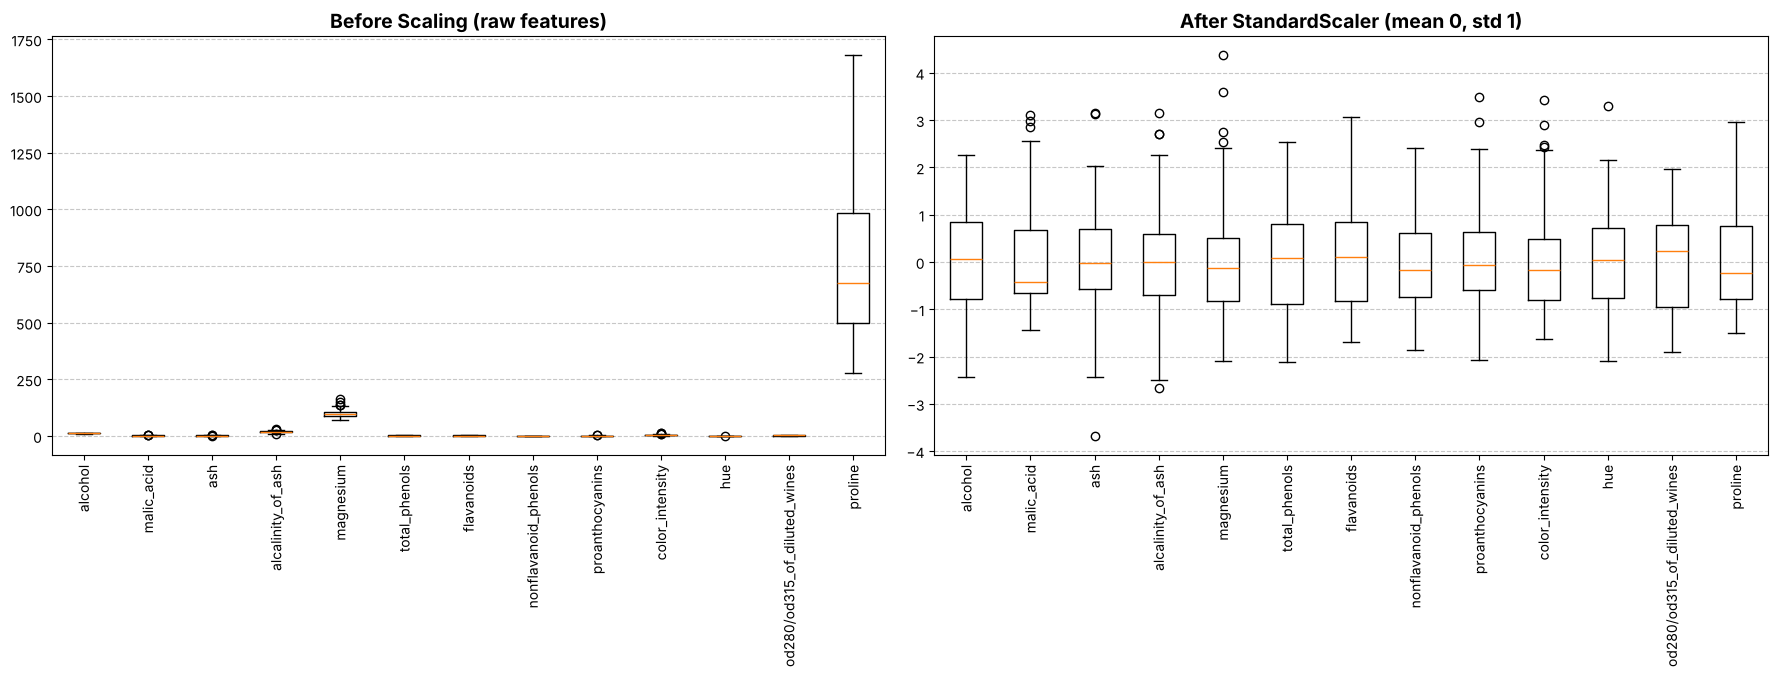

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

# Load the wine dataset as a pandas DataFrame for ease of analysis
wine = load_wine(as_frame=True)
X = wine.data
y = wine.target

# Display basic dataset dimensions and class distribution
print("Dataset Shape (Samples, Features):", X.shape)
print("Target Classes:", wine.target_names)
print("\nClass Distribution:\n", pd.Series(y).value_counts().sort_index())

# Display the first few rows and the summary statistics of the feature matrix
display(X.head())
display(X.describe().T)

# Check for missing values
print("\nMissing values per column:\n", X.isnull().sum())
print("Total missing values:", X.isnull().sum().sum())

# Standardize all 13 features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Compare the mean and standard deviation of each feature before and after scaling
comparison = pd.DataFrame({
    "Mean (raw)": X.mean(),
    "Std (raw)": X.std(),
    "Mean (scaled)": X_scaled.mean(axis=0),
    "Std (scaled)": X_scaled.std(axis=0, ddof=1),
}, index=X.columns).round(3)
print("\nFeature mean and standard deviation before and after scaling:\n", comparison)

# Share of the squared distance between two wines contributed by each raw feature
share = (X.var() / X.var().sum() * 100).sort_values(ascending=False)
print("\nShare of the squared distance contributed by each RAW feature (%):\n", share.round(2))

# Boxplots before and after scaling
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
axes[0].boxplot(X.values, tick_labels=X.columns)
axes[0].set_title("Before Scaling (raw features)", fontweight="bold")
axes[1].boxplot(X_scaled, tick_labels=X.columns)
axes[1].set_title("After StandardScaler (mean 0, std 1)", fontweight="bold")
for ax in axes:
    ax.tick_params(axis="x", rotation=90)
    ax.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

Task 2: Iterate k from 1 to 10 for K-Means clustering on the scaled features. Compute and plot side-by-side the Elbow Method curve and the Silhouette Scores curve for k in [2, 10]. Print the optimal k value suggested by both metrics.

Explanation: Fits a KMeans model on the scaled features for every k from 1 to 10 and saves the inertia of each one. The silhouette score is computed for k from 2 to 10, because it needs at least 2 clusters. The elbow is picked as the k whose point is farthest from the straight line joining the first and last point of the inertia curve, and the best silhouette k is the one with the highest score. The two curves are plotted side by side with the chosen k marked, and the optimal k from both metrics is printed.

k        Inertia    Silhouette
1        2314.00             -
2        1658.76        0.2593
3        1277.93        0.2849
4        1175.43        0.2602
5        1109.51        0.2016
6        1046.00        0.2372
7         981.60        0.2036
8         935.20        0.1570
9         889.89        0.1499
10        845.90        0.1436

Optimal k suggested by the Elbow Method:     3
Optimal k suggested by the Silhouette Score: 3


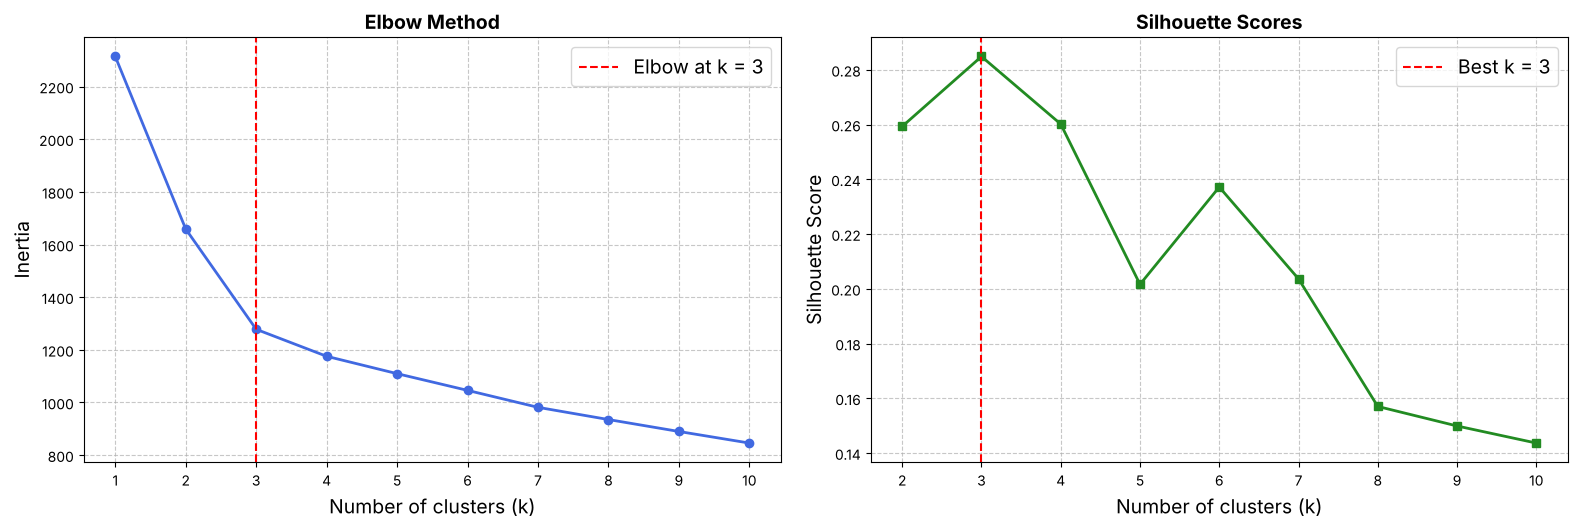

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Fit K-Means for k from 1 to 10 on the scaled features
k_values = range(1, 11)
inertias = []
sil_scores = {}

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    if k >= 2:
        sil_scores[k] = silhouette_score(X_scaled, labels)

# Elbow: the k farthest from the line joining the first and last points of the inertia curve
ks = np.array(list(k_values), dtype=float)
iner = np.array(inertias)
p1 = np.array([ks[0], iner[0]])
p2 = np.array([ks[-1], iner[-1]])
line = (p2 - p1) / np.linalg.norm(p2 - p1)
pts = np.column_stack([ks, iner]) - p1
dist_to_line = np.abs(pts[:, 0] * line[1] - pts[:, 1] * line[0])
elbow_k = int(ks[np.argmax(dist_to_line)])

# Silhouette: the k with the highest score
best_sil_k = max(sil_scores, key=sil_scores.get)

# Plot the two curves side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
axes[0].plot(list(k_values), inertias, marker="o", color="royalblue", linewidth=2)
axes[0].axvline(elbow_k, color="red", linestyle="--", label=f"Elbow at k = {elbow_k}")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Method", fontweight="bold")
axes[0].set_xticks(list(k_values))
axes[1].plot(list(sil_scores.keys()), list(sil_scores.values()), marker="s", color="forestgreen", linewidth=2)
axes[1].axvline(best_sil_k, color="red", linestyle="--", label=f"Best k = {best_sil_k}")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Scores", fontweight="bold")
axes[1].set_xticks(list(sil_scores.keys()))
for ax in axes:
    ax.legend()
    ax.grid(linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

print(f"{'k':<4}{'Inertia':>12}{'Silhouette':>14}")
for k, i in zip(k_values, inertias):
    s = f"{sil_scores[k]:.4f}" if k >= 2 else "-"
    print(f"{k:<4}{i:>12.2f}{s:>14}")
print(f"\nOptimal k suggested by the Elbow Method:     {elbow_k}")
print(f"Optimal k suggested by the Silhouette Score: {best_sil_k}")

Task 3: Apply PCA strictly to reduce the 13 scaled features down to 2 principal components for visualization purposes. Fit a K-Means model (k=3) on the 2D projected space. Plot the decision boundaries using the Voronoi method.

Explanation: Reduces the 13 scaled features to 2 principal components with PCA, which is only used for the picture, and prints the variance they keep. I then fit a KMeans model with k=3 on the 2D data. K-Means gives every point to its nearest centroid, so the decision regions are the Voronoi cells of the centroids. The regions are colored by predicting the cluster of every point on a grid, the Voronoi edges are drawn on top with scipy's Voronoi and voronoi_plot_2d, and the wines and the centroids are plotted over them.

Variance explained by PC1 and PC2: [36.2  19.21] %
Total variance kept by 2 components: 55.41 %


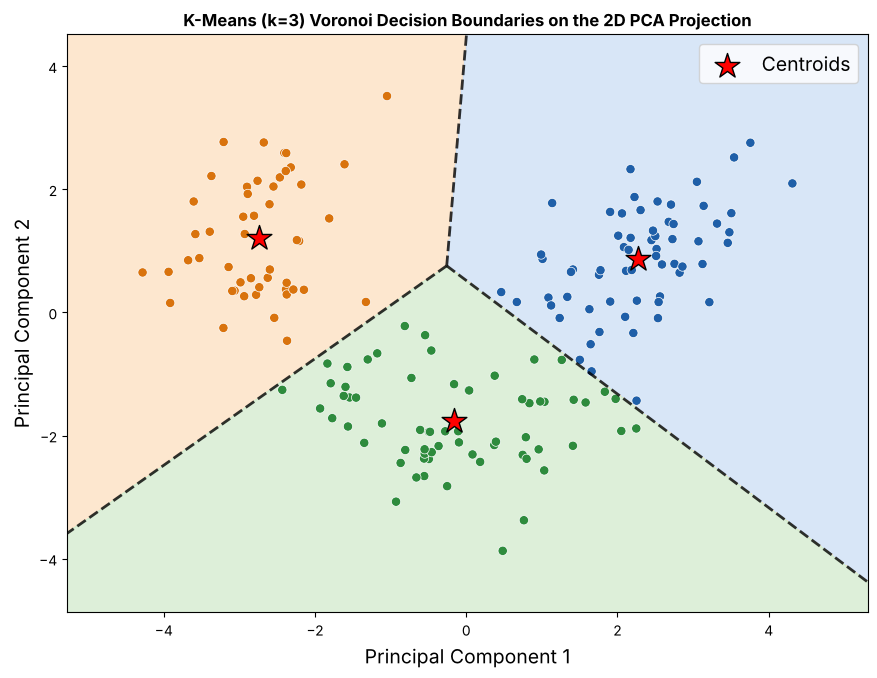

In [ ]:
from matplotlib.colors import ListedColormap
from scipy.spatial import Voronoi, voronoi_plot_2d
from sklearn.decomposition import PCA

# Reduce the 13 scaled features to 2 principal components (for visualization only)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print("Variance explained by PC1 and PC2:", (pca.explained_variance_ratio_ * 100).round(2), "%")
print("Total variance kept by 2 components:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

# Fit K-Means (k=3) on the 2D projected space
km2d = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_2d = km2d.fit_predict(X_pca)
centroids_2d = km2d.cluster_centers_

# Predict the cluster of every point on a grid to color the Voronoi regions
x_min, x_max = X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1
y_min, y_max = X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))
Z = km2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

# Plot the regions, the Voronoi edges, the wines and the centroids
plt.figure(figsize=(9, 7))
plt.contourf(xx, yy, Z, cmap=ListedColormap(["#cfe0f5", "#fde2c4", "#d5ecd0"]), alpha=0.8)
voronoi_plot_2d(Voronoi(centroids_2d), ax=plt.gca(), show_points=False, show_vertices=False,
                line_colors="black", line_width=2, line_alpha=0.8)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_2d, cmap=ListedColormap(["#1f5fa8", "#d9730d", "#2e8b3d"]),
            edgecolor="white", linewidth=0.5, s=45)
plt.scatter(centroids_2d[:, 0], centroids_2d[:, 1], marker="*", s=350, c="red", edgecolor="black", label="Centroids")
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means (k=3) Voronoi Decision Boundaries on the 2D PCA Projection", fontsize=12, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()

Task 4: Select 5 representative wine samples from the dataset. Using the fitted 13-feature K-Means model (k=3), compute the distance matrix. Generate and display a heatmap visualizing the soft clustering distance profiles across all 3 cluster centroids, highlighting the minimum distance corresponding to each sample's hard cluster assignment.

Explanation: Fits a KMeans model with k=3 on the full 13 scaled features and uses transform() to get the distance from every wine to every centroid. I selected 5 wines: the wine closest to the centroid of each cluster (the 3 most typical wines) and the 2 wines whose two closest centroids are almost the same distance away (the 2 most ambiguous wines). The 5 x 3 distance matrix is printed with each wine's hard cluster, true cultivar and the margin between its closest and second closest centroid. It is then drawn as a heatmap, and the minimum distance in each row, which is the hard assignment, is outlined with a red box.

Distance matrix (5 wines x 3 centroids):
           Centroid 0  Centroid 1  Centroid 2  Hard cluster  True cultivar  Margin (2nd - 1st)
Wine 106       1.548       4.268       4.305             0              1               2.721
Wine 148       4.495       1.079       5.298             1              2               3.415
Wine 48        3.815       4.869       1.343             2              0               2.472
Wine 61        3.521       3.397       5.250             1              1               0.124
Wine 121       6.327       7.476       6.162             2              1               0.165


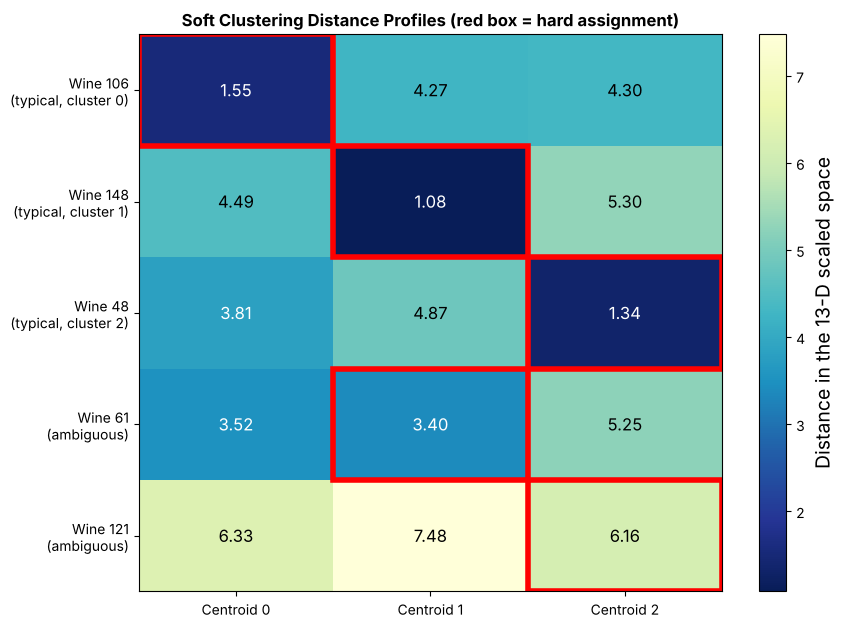

In [ ]:
from matplotlib.patches import Rectangle

# Fit K-Means (k=3) on the full 13 scaled features
km13 = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_km = km13.fit_predict(X_scaled)

# Distance from every wine to every centroid
dist_all = km13.transform(X_scaled)

# Select the 3 most typical wines (closest to each centroid) and the 2 most ambiguous wines
typical = [int(np.argmin(np.where(labels_km == c, dist_all[:, c], np.inf))) for c in range(3)]
sorted_d = np.sort(dist_all, axis=1)
margin = sorted_d[:, 1] - sorted_d[:, 0]
ambiguous = [int(i) for i in np.argsort(margin) if i not in typical][:2]
idx = typical + ambiguous
row_names = [f"Wine {i}\n(typical, cluster {labels_km[i]})" for i in typical] + \
            [f"Wine {i}\n(ambiguous)" for i in ambiguous]

# Print the 5 x 3 distance matrix
D = dist_all[idx]
profile = pd.DataFrame(D, index=[f"Wine {i}" for i in idx], columns=[f"Centroid {c}" for c in range(3)]).round(3)
profile["Hard cluster"] = labels_km[idx]
profile["True cultivar"] = y.values[idx]
profile["Margin (2nd - 1st)"] = margin[idx].round(3)
print("Distance matrix (5 wines x 3 centroids):\n", profile)

# Plot the distance matrix as a heatmap and outline the minimum of each row
fig, ax = plt.subplots(figsize=(9, 6.5))
im = ax.imshow(D, cmap="YlGnBu_r", aspect="auto")
for r in range(D.shape[0]):
    for c in range(D.shape[1]):
        ax.text(c, r, f"{D[r, c]:.2f}", ha="center", va="center", fontsize=12,
                color="white" if D[r, c] < D.mean() else "black")
    best = int(np.argmin(D[r]))
    ax.add_patch(Rectangle((best - 0.5, r - 0.5), 1, 1, fill=False, edgecolor="red", linewidth=4))
ax.set_xticks(range(3))
ax.set_xticklabels([f"Centroid {c}" for c in range(3)])
ax.set_yticks(range(5))
ax.set_yticklabels(row_names)
ax.set_title("Soft Clustering Distance Profiles (red box = hard assignment)", fontsize=12, fontweight="bold")
fig.colorbar(im, ax=ax, label="Distance in the 13-D scaled space")
plt.tight_layout()
plt.show()

Task 5: Fit a DBSCAN model on the 13-dimensional scaled feature space. Experiment with the two needed hyperparameter settings. Print the number of identified clusters and noise points. Visualize the DBSCAN assignments on the 2D PCA projection space, clearly distinguishing noise points from core cluster members.

Explanation: Runs DBSCAN on the 13 scaled features for a grid of eps values (1.5 to 3.5) and min_samples values (3, 5, 10) and prints the number of clusters, noise points and the noise percentage for each setting. I then chose the setting with the highest silhouette score on the non-noise wines, among settings with at least 2 clusters and less than 40% noise, so that a setting that throws most of the data away is not picked. The chosen model is refit and the number of clusters, the number of noise points and the true cultivars of the noise points are printed. The assignments are plotted on the 2D PCA projection from Task 3, with cluster members as colored dots and noise points as black crosses.

 eps  min_samples  clusters  noise points  noise %  silhouette (non-noise)
1.50            3         8           147     82.6                  0.3311
2.00            3         5            64     36.0                  0.2113
2.25            3         2            37     20.8                  0.3313
2.50            3         1            23     12.9                     NaN
2.75            3         1            16      9.0                     NaN
3.00            3         2             7      3.9                  0.2392
3.50            3         2             3      1.7                  0.2308
1.50            5         0           178    100.0                     NaN
2.00            5         5            85     47.8                  0.2405
2.25            5         2            46     25.8                  0.3371
2.50            5         1            24     13.5                     NaN
2.75            5         1            17      9.6                     NaN
3.00            5        

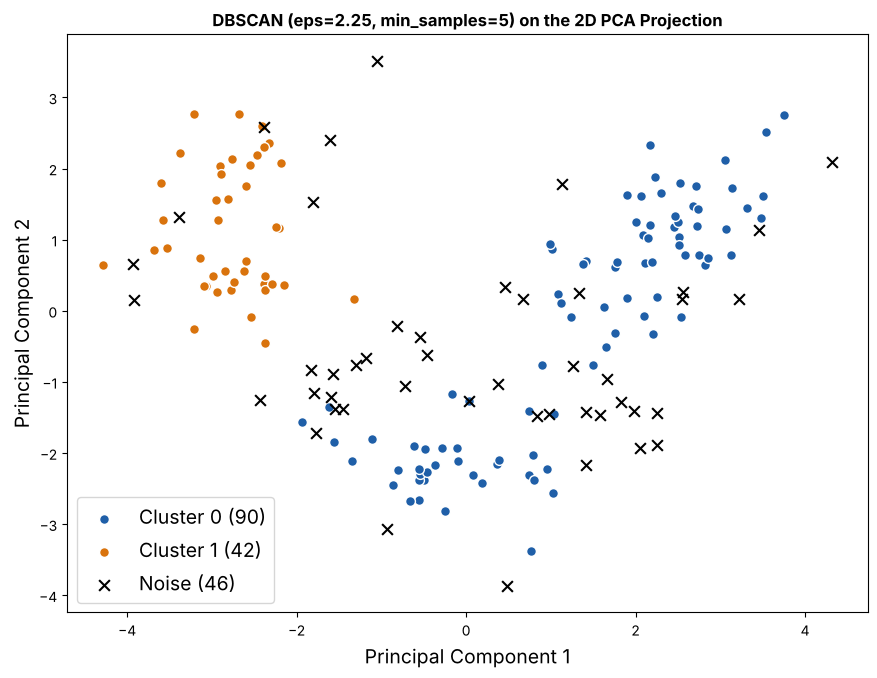

In [ ]:
from sklearn.cluster import DBSCAN

# Experiment with the two hyperparameters: eps and min_samples
eps_values = [1.5, 2.0, 2.25, 2.5, 2.75, 3.0, 3.5]
min_samples_values = [3, 5, 10]

rows = []
for ms in min_samples_values:
    for eps in eps_values:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        n_noise = int((lab == -1).sum())
        mask = lab != -1
        sil = silhouette_score(X_scaled[mask], lab[mask]) if n_cl >= 2 else np.nan
        rows.append({"eps": eps, "min_samples": ms, "clusters": n_cl, "noise points": n_noise,
                     "noise %": round(n_noise / len(lab) * 100, 1),
                     "silhouette (non-noise)": round(sil, 4) if n_cl >= 2 else np.nan})
grid = pd.DataFrame(rows)
print(grid.to_string(index=False))

# Select the best silhouette among settings with at least 2 clusters and less than 40% noise
valid = grid[(grid["clusters"] >= 2) & (grid["noise %"] < 40)]
best = valid.sort_values("silhouette (non-noise)", ascending=False).iloc[0]
best_eps, best_ms = float(best["eps"]), int(best["min_samples"])
print(f"\nSelected hyperparameters: eps = {best_eps}, min_samples = {best_ms}")

# Fit DBSCAN with the selected hyperparameters
db = DBSCAN(eps=best_eps, min_samples=best_ms)
labels_db = db.fit_predict(X_scaled)
n_clusters_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise_db = int((labels_db == -1).sum())
print(f"Number of clusters found: {n_clusters_db}")
print(f"Number of noise points:   {n_noise_db}")
print("True cultivars of the noise points:", y[labels_db == -1].value_counts().sort_index().to_dict())
print("Cluster sizes:", pd.Series(labels_db[labels_db != -1]).value_counts().sort_index().to_dict())

# Plot cluster members and noise points on the 2D PCA projection
plt.figure(figsize=(9, 7))
palette = ["#1f5fa8", "#d9730d", "#2e8b3d", "#8e44ad", "#c0392b"]
for i, c in enumerate(sorted(set(labels_db) - {-1})):
    m = labels_db == c
    plt.scatter(X_pca[m, 0], X_pca[m, 1], s=50, color=palette[i % len(palette)], edgecolor="white", label=f"Cluster {c} ({m.sum()})")
noise_mask = labels_db == -1
plt.scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1], marker="x", s=60, color="black", label=f"Noise ({noise_mask.sum()})")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(f"DBSCAN (eps={best_eps}, min_samples={best_ms}) on the 2D PCA Projection", fontsize=12, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()

Task 6: Fit an HDBSCAN model (using min_cluster_size=5 or min_samples=5) on the 13-dimensional scaled feature space. Print the total number of clusters discovered and noise points detected. Visualize the resulting HDBSCAN cluster assignments on the 2D PCA projection space.

Explanation: Fits sklearn's HDBSCAN with min_cluster_size=5 and min_samples=5 on the 13 scaled features. It prints the number of clusters, the number of noise points, the cluster sizes and the true cultivars of the noise points. The assignments are plotted on the same 2D PCA projection as Task 5, with cluster members as colored dots and noise points as black crosses.

Number of clusters discovered: 2
Number of noise points:        58
Cluster sizes: {0: 86, 1: 34}
True cultivars of the noise points: {0: 6, 1: 37, 2: 15}


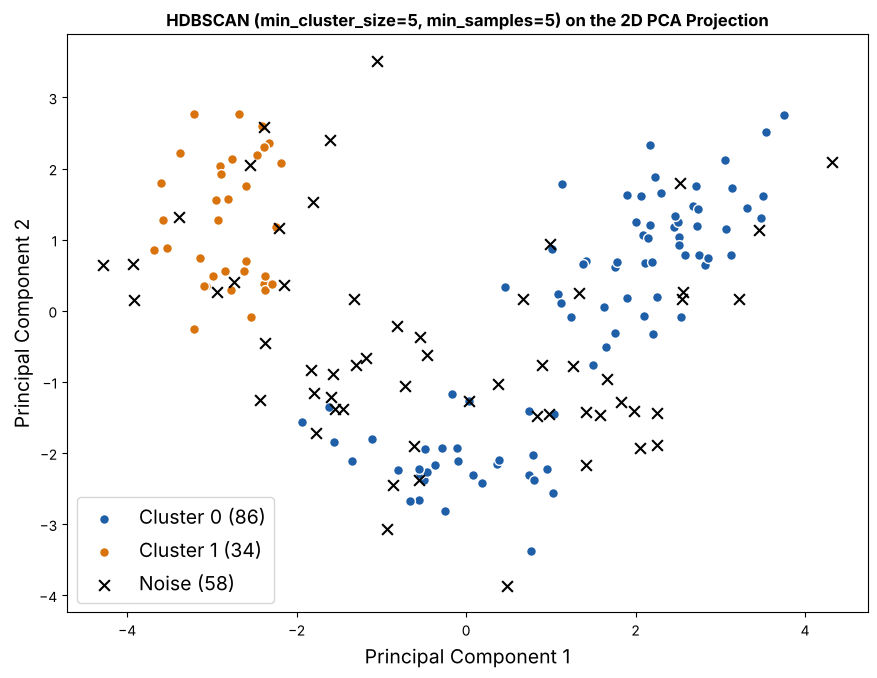

In [ ]:
from sklearn.cluster import HDBSCAN

# Fit HDBSCAN on the 13 scaled features
hdb = HDBSCAN(min_cluster_size=5, min_samples=5, copy=True)
labels_hdb = hdb.fit_predict(X_scaled)
n_clusters_hdb = len(set(labels_hdb)) - (1 if -1 in labels_hdb else 0)
n_noise_hdb = int((labels_hdb == -1).sum())
print(f"Number of clusters discovered: {n_clusters_hdb}")
print(f"Number of noise points:        {n_noise_hdb}")
print("Cluster sizes:", pd.Series(labels_hdb[labels_hdb != -1]).value_counts().sort_index().to_dict())
print("True cultivars of the noise points:", y[labels_hdb == -1].value_counts().sort_index().to_dict())

# Plot cluster members and noise points on the 2D PCA projection
plt.figure(figsize=(9, 7))
palette = ["#1f5fa8", "#d9730d", "#2e8b3d", "#8e44ad", "#c0392b", "#16a0a0", "#7f8c8d"]
for i, c in enumerate(sorted(set(labels_hdb) - {-1})):
    m = labels_hdb == c
    plt.scatter(X_pca[m, 0], X_pca[m, 1], s=50, color=palette[i % len(palette)], edgecolor="white", label=f"Cluster {c} ({m.sum()})")
noise_mask = labels_hdb == -1
plt.scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1], marker="x", s=60, color="black", label=f"Noise ({noise_mask.sum()})")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("HDBSCAN (min_cluster_size=5, min_samples=5) on the 2D PCA Projection", fontsize=12, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()

Task 7: Compute a single-linkage hierarchical clustering matrix on the scaled Wine features. Plot a hierarchical clustering dendrogram to visualize how individual chemical profiles merge across distance thresholds, connecting the visual structure to HDBSCAN's stability extraction mechanics.

Explanation: Computes the single-linkage matrix of the scaled features with scipy's linkage and plots it with dendrogram, so that the height of each merge is the distance at which two groups of wines join. A red dashed line marks the eps chosen for DBSCAN in Task 5, and I print the largest merge distances, the median merge distance and the number of groups left if the tree is cut at that eps. HDBSCAN works on this same tree, but instead of cutting it at one height it removes branches smaller than min_cluster_size and keeps the clusters that stay separate over the longest range of distances.

Last 8 merge distances: [2.979 3.009 3.312 3.429 3.641 3.86  3.908 4.003]
Median merge distance: 1.825
Number of groups left if the tree is cut at the DBSCAN eps: 35


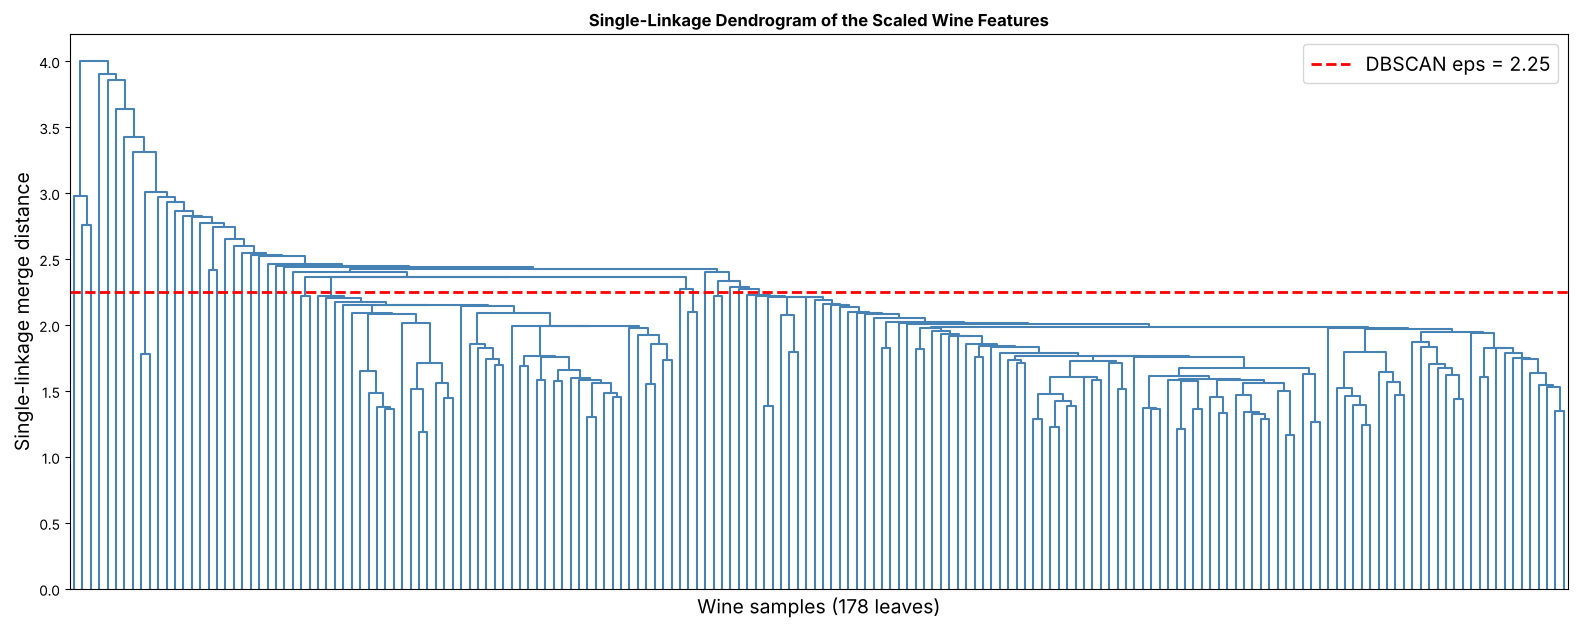

In [ ]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage

# Compute the single-linkage matrix on the scaled features
Z_single = linkage(X_scaled, method="single")

# Plot the dendrogram with the DBSCAN eps as a horizontal line
plt.figure(figsize=(16, 6.5))
dendrogram(Z_single, no_labels=True, color_threshold=0, above_threshold_color="steelblue")
plt.axhline(best_eps, color="red", linestyle="--", linewidth=2, label=f"DBSCAN eps = {best_eps}")
plt.xlabel("Wine samples (178 leaves)")
plt.ylabel("Single-linkage merge distance")
plt.title("Single-Linkage Dendrogram of the Scaled Wine Features", fontsize=12, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()

print("Last 8 merge distances:", np.round(Z_single[-8:, 2], 3))
print("Median merge distance:", round(float(np.median(Z_single[:, 2])), 3))
print("Number of groups left if the tree is cut at the DBSCAN eps:",
      len(set(fcluster(Z_single, t=best_eps, criterion="distance"))))

Task 8: Treat the cluster assignments generated by K-Means (k=3), DBSCAN, and HDBSCAN as categorical feature representations or pseudo-labels. Perform a stratified train/test split (80/20) on the Wine dataset and conduct an experiment: train a supervised classifier such as a Random Forest or Logistic Regression using these cluster labels to predict the actual ground-truth wine cultivars (Class 0, 1, 2). Plot the classification accuracy and Silhouette Scores for all three algorithms.

Explanation: One-hot encodes the cluster labels of K-Means, DBSCAN and HDBSCAN, keeping the noise label (-1) as its own category so that those wines are not dropped. The wines are split 80/20 with stratify on the true cultivar, and a Logistic Regression is trained on each set of cluster labels to predict the cultivar. The test accuracy is recorded, and the silhouette score of each algorithm is computed on the scaled features (only on the non-noise wines for DBSCAN and HDBSCAN). A table is printed, and the accuracies and silhouette scores are plotted in two bar charts side by side.

K-Means (k=3)             Accuracy: 0.9722   Silhouette: 0.2849   Noise points: 0
DBSCAN                    Accuracy: 0.8056   Silhouette: 0.3371   Noise points: 46
HDBSCAN                   Accuracy: 0.7500   Silhouette: 0.3524   Noise points: 58


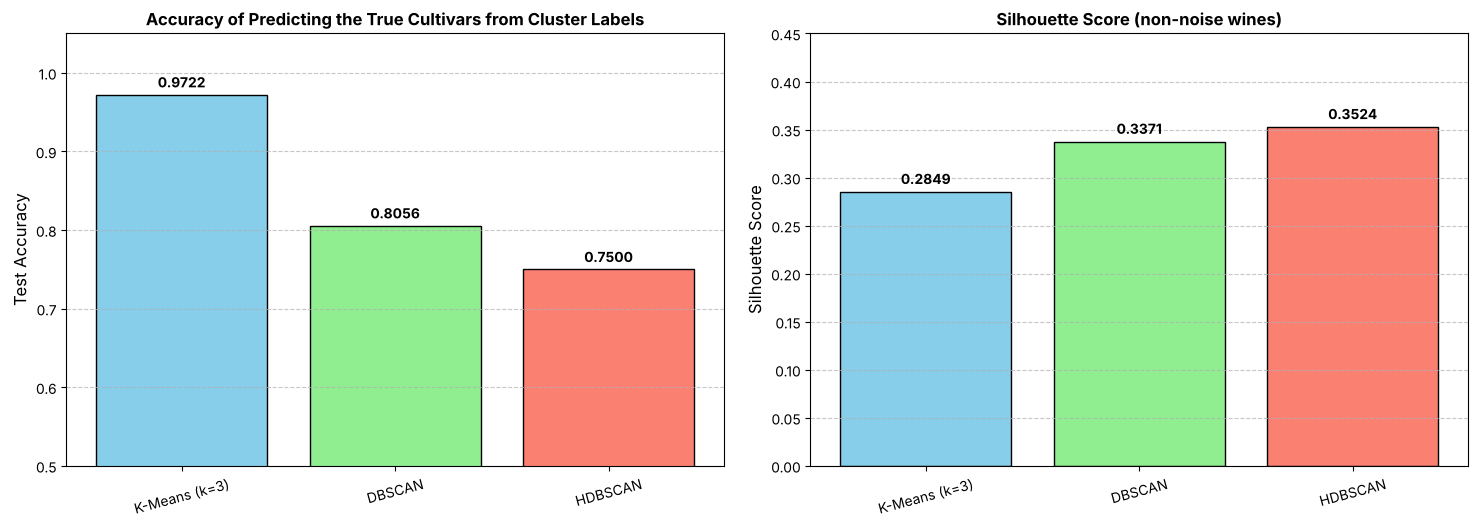

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# Cluster assignments from the three algorithms used as pseudo-labels
pseudo = {
    "K-Means (k=3)": labels_km,
    "DBSCAN": labels_db,
    "HDBSCAN": labels_hdb,
}

names = []
accuracies = []
silhouettes = []

# One-hot encode each set of labels (noise = -1 is kept as its own category), then split 80/20
for name, lab in pseudo.items():
    X_cluster = pd.get_dummies(pd.Series(lab).astype("category"), prefix="cluster").astype(float)
    X_train, X_test, y_train, y_test = train_test_split(
        X_cluster, y, test_size=0.2, random_state=42, stratify=y
    )

    # Train and evaluate the classifier on the cluster labels
    clf = LogisticRegression(random_state=42, max_iter=5000)
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    # Silhouette score on the scaled features (non-noise wines only)
    mask = lab != -1
    sil = silhouette_score(X_scaled[mask], lab[mask])

    names.append(name)
    accuracies.append(acc)
    silhouettes.append(sil)
    print(f"{name:<25} Accuracy: {acc:.4f}   Silhouette: {sil:.4f}   Noise points: {(~mask).sum()}")

# Create the bar plots
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, vals, label, ylim in zip(axes, [accuracies, silhouettes],
                                 ["Test Accuracy", "Silhouette Score"], [(0.5, 1.05), (0, 0.45)]):
    bars = ax.bar(names, vals, color=["skyblue", "lightgreen", "salmon"], edgecolor="black")
    ax.set_ylabel(label, fontsize=12)
    ax.set_ylim(*ylim)
    ax.grid(axis="y", linestyle="--", alpha=0.7)
    ax.tick_params(axis="x", rotation=15)
    # Annotate values on top of each bar
    for bar in bars:
        yval = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, yval + 0.005, f"{yval:.4f}",
                ha="center", va="bottom", fontsize=10, fontweight="bold")
axes[0].set_title("Accuracy of Predicting the True Cultivars from Cluster Labels", fontsize=12, fontweight="bold")
axes[1].set_title("Silhouette Score (non-noise wines)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()